## Random Forest

In [1]:
# Load Libraries
import warnings
warnings.filterwarnings("ignore")
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from evaluation_script import evaluate_model

### Loading data

In [6]:
# Load Processed Data
data = joblib.load('../building/dataset_bundle.pkl')

X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']


hi


#### Finding The Best Parameters

In [8]:
param_grid = {
    'max_depth': [5, 7, 9],
    'max_features': [4, 6, 8],
    'n_estimators': [50, 100],
    'min_samples_split': [3, 5]
}


In [9]:
# Create Search Space
RanFor_grid = GridSearchCV(RandomForestClassifier(class_weight="balanced"), 
                           param_grid, 
                           cv = 5, 
                           refit = True, 
                           scoring = 'f1',
                           verbose = 1)
print("done")

done


#### Fit Best Model On Training Data

In [ ]:
RanFor_grid.fit(X_train , y_train)
best_model = RanFor_grid.best_estimator_
best_model
print("done")

In [11]:
RandomForestClassifier(class_weight='balanced', max_depth=8, max_features=8,
min_samples_split=3) 
print("done")

done


#### Evaluate On Testing 

In [12]:
evaluate_model(best_model, X_test, y_test)

{'Recall_Churn': 0.660427807486631,
 'Precision_Churn': 0.49007936507936506,
 'F1_Churn': 0.5626423690205011,
 'ROC_AUC': 0.8294772118844183}

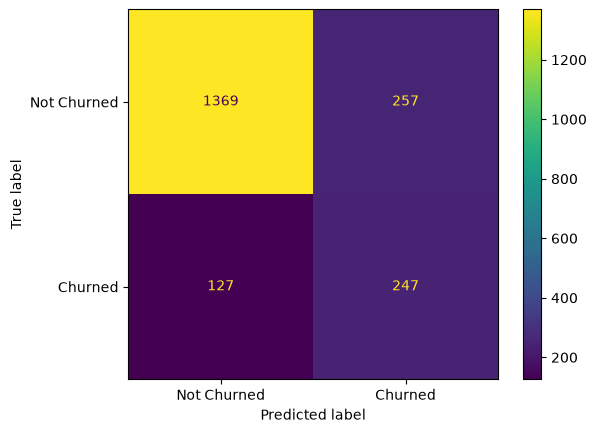

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = RanFor_grid.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Churned", "Churned"]
)

plt.show()